In [2]:
## using my_env 
import xarray as xr
import matplotlib.pyplot as plt
import geopandas as gpd
import numpy as np
from scipy.ndimage import gaussian_filter
import pandas as pd
import elr_c as elr
import utils_b as utils
from sklearn.metrics import roc_auc_score

In [3]:
import numpy as np
import xarray as xr

def compute_igss_grid(forecast_probs_xr, observations_xr, epsilon=1e-6):
    """
    Compute Ignorance Skill Score (IGSS) for each grid point using
    time series of forecast probabilities and one-hot observations.

    Parameters
    ----------
    forecast_probs_xr : xarray.DataArray (T, category, Y, X)
        Forecast probabilities for 3 tercile categories:
        [below, normal, above]

    observations_xr : xarray.DataArray (T, category, Y, X)
        One-hot encoded observations (1 for observed category, 0 otherwise)

    epsilon : float
        Small value to avoid log2(0)

    Returns
    -------
    igss_map : xarray.DataArray (Y, X)
        Ignorance Skill Score at each spatial grid point
    """

    T, C, Y, X = forecast_probs_xr.shape

    if C != 3:
        raise ValueError("This function assumes tercile forecasts with 3 categories.")

    igss_array = np.full((Y, X), np.nan)

    # Climatological ignorance for terciles
    ig_clim = -np.log2(1.0 / 3.0)  # ~1.585

    for i in range(Y):
        for j in range(X):
            forecast_probs = forecast_probs_xr[:, :, i, j].values  # shape (T, 3)
            obs_onehot = observations_xr[:, :, i, j].values        # shape (T, 3)

            # Skip grid if all values are missing
            if np.all(np.isnan(forecast_probs)) or np.all(np.isnan(obs_onehot)):
                continue

            # Convert one-hot observations to observed class index
            obs_class = np.argmax(obs_onehot, axis=1)  # shape (T,)

            # Clip probabilities to avoid log(0)
            forecast_probs = np.clip(forecast_probs, epsilon, 1.0)

            # Extract probability assigned to the observed category
            p_obs = forecast_probs[np.arange(T), obs_class]

            # Remove invalid time steps if needed
            valid_mask = np.isfinite(p_obs)
            if np.sum(valid_mask) == 0:
                continue

            p_obs_valid = p_obs[valid_mask]

            # Mean forecast ignorance
            ig_forecast = np.mean(-np.log2(p_obs_valid))

            # Ignorance Skill Score
            igss_array[i, j] = 1.0 - (ig_forecast / ig_clim)

    igss_map = xr.DataArray(
        igss_array,
        dims=("Y", "X"),
        coords={
            "Y": forecast_probs_xr.coords["Y"],
            "X": forecast_probs_xr.coords["X"]
        },
        name="IGSS"
    )

    return igss_map


In [4]:
def smooth_xarray_with_nan(data, sigma=1):
    nan_mask = np.isnan(data)
    filled_data = data.fillna(data.mean())
    smoothed = gaussian_filter(filled_data, sigma=sigma)
    smoothed_data = xr.DataArray(smoothed, coords=data.coords, dims=data.dims)
    smoothed_data = smoothed_data.where(~nan_mask)
    return smoothed_data

In [5]:
# Load the shapefile
shapefile_path = "/Users/bohar/Documents/ELR_IRI2/shapes/indian_borders.shp"  # Update with your actual file path
State_shapefile_path = "/Users/bohar/Documents/ELR_IRI2/shapes/sd_boundary.shp"  # Update with your actual file path
gdf = gpd.read_file(shapefile_path)
gdf_st = gpd.read_file(State_shapefile_path)

In [6]:
weekn =34

In [7]:
elr_probs = xr.open_dataset(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_prob_Week{weekn}_2022_2024.nc')['prcp']
qrf_prob =np.load(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/week_{weekn}_tuned_terciles_2022_2024.npy')
classes = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_category_Week{weekn}_2022_2024.nc")['prcp']


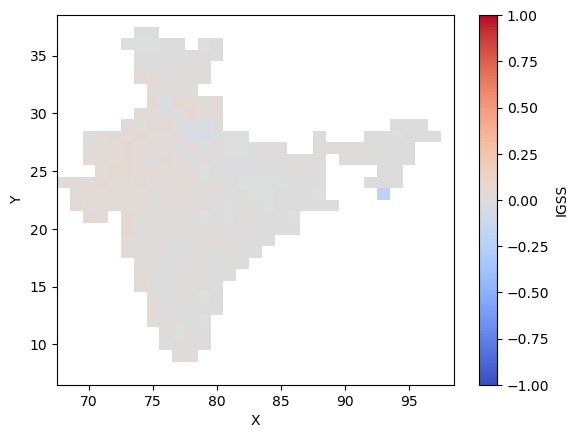

In [8]:
groc_result = compute_igss_grid(elr_probs, classes, epsilon=1e-6)
groc_result.plot(cmap = 'coolwarm', vmin=-1.0, vmax=1.0)  # For visualization

In [9]:
qrf_prob_rotated = np.transpose(qrf_prob, axes=(2, 3, 0, 1))
qrf_probs = xr.DataArray(
    qrf_prob_rotated,
    dims=elr_probs.dims,  # ('T', 'category', 'Y', 'X')
    coords=elr_probs.coords,
    name="qrf_probs"
)
#qrf_probs

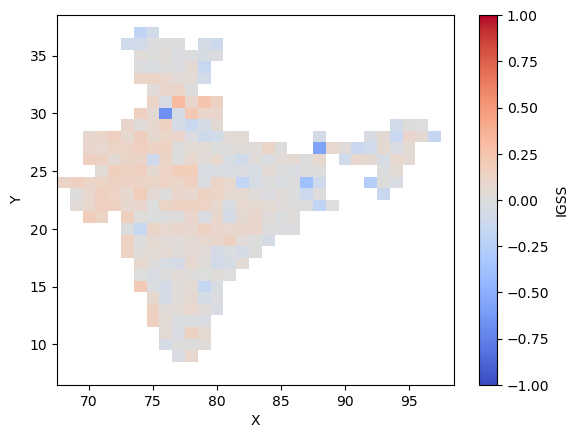

In [10]:
groc_result = compute_igss_grid(qrf_probs, classes, epsilon=1e-6)
groc_result.plot(cmap = 'coolwarm', vmin=-1.0, vmax=1.0)  # For visualization

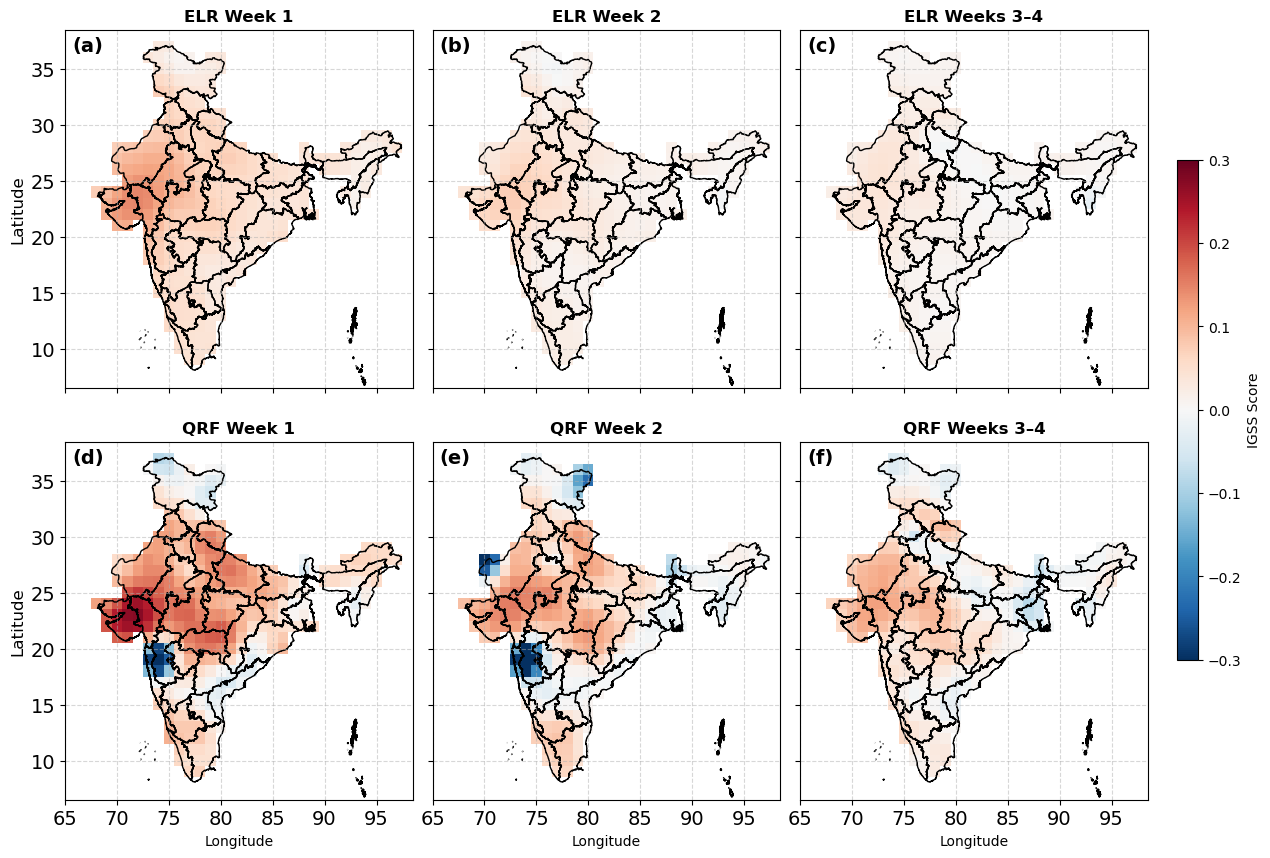

In [11]:
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

# Define weeks and titles
weekn = [1, 2, 34]
titles = ['Week 1', 'Week 2', 'Weeks 3–4']
title_fontsize = 12

# Set up 2x3 subplot layout
fig, axes = plt.subplots(2, 3, figsize=(14, 10), sharex=True, sharey=True)
plt.subplots_adjust(wspace=0.05, hspace=0.15)

# Colorbar settings
orange_cmap = 'RdBu_r'
groc_vmin, groc_vmax = -0.3, 0.3

for i, (week, title) in enumerate(zip(weekn, titles)):
    # Load data
    elr_probs = xr.open_dataset(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_prob_Week{week}_2022_2024.nc')['prcp']
    qrf_prob = np.load(f'/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/QRF_output/week_{week}_tuned_terciles_2022_2024.npy')
    classes = xr.open_dataset(f"/Users/bohar/Documents/abstract_papers/QRF/monsoon_data/ELR_output/ELR_test_category_Week{week}_2022_2024.nc")['prcp']
    # Coordinate extraction
    Y = elr_probs.coords["Y"]
    X = elr_probs.coords["X"]
    T = elr_probs.coords["T"]
    # Reformat QRF probabilities
    qrf_prob_rotated = np.transpose(qrf_prob, axes=(2, 3, 0, 1))  # shape: T, category, Y, X
    qrf_probs = xr.DataArray(
        qrf_prob_rotated,
        dims=elr_probs.dims,
        coords=elr_probs.coords,
        name="qrf_probs"
    )

    # Compute GROC for both methods
    groc_elr = compute_igss_grid(elr_probs, classes, epsilon=1e-6)
    groc_qrf = compute_igss_grid(qrf_probs, classes, epsilon=1e-6)

    # Smooth GROC fields
    smelr_groc = smooth_xarray_with_nan(groc_elr, sigma=1)
    smqrf_groc = smooth_xarray_with_nan(groc_qrf, sigma=1)

    # Top row → ELR
    ax_elr = axes[0, i]
    im_elr = smelr_groc.plot(
        ax=ax_elr, cmap=orange_cmap, vmin=groc_vmin, vmax=groc_vmax,
        add_colorbar=False
    )
    gdf_st.plot(ax=ax_elr, color="none", edgecolor="black", linewidth=1)
    ax_elr.set_title(f"ELR {title}", fontsize=title_fontsize,weight='bold')

    # Bottom row → QRF
    ax_qrf = axes[1, i]
    im_qrf = smqrf_groc.plot(
        ax=ax_qrf, cmap=orange_cmap, vmin=groc_vmin, vmax=groc_vmax,
        add_colorbar=False
    )
    gdf_st.plot(ax=ax_qrf, color="none", edgecolor="black", linewidth=1)
    ax_qrf.set_title(f"QRF {title}", fontsize=title_fontsize,weight='bold')
    # Add labels (a), (b), (c), ... in the top-left corner
i=0
for ax in axes.flatten():
    ax.tick_params(axis='both', labelsize=14)
    ax.grid(True, linestyle="--", alpha=0.5)    
    ax.text(0.02, 0.98, f"({chr(97 + i)})", transform=ax.transAxes, 
            fontsize=14, weight='bold', va='top', ha='left', color='black')
    i=i+1
# Shared colorbar on the right
cbar_ax = fig.add_axes([0.92, 0.25, 0.015, 0.5])
fig.colorbar(im_elr, cax=cbar_ax, label='IGSS Score')

# Add Y-axis labels
axes[0, 0].set_ylabel('ELR', fontsize=12)
axes[1, 0].set_ylabel('QRF', fontsize=12)

# **Set axis labels only where necessary**
for row in range(2):
    for col in range(3):
        if col == 0:  # Latitude labels only for leftmost column
            axes[row, col].set_ylabel("Latitude")
        else:
            axes[row, col].set_ylabel("")  # Remove unnecessary labels

for col in range(3):
    for row in range(2):
        if row == 1:  # Longitude labels only for bottom row
            axes[row, col].set_xlabel("Longitude")
        else:
            axes[row, col].set_xlabel("")  # Remove unnecessary labels
            
min_longitude, max_longitude = X.min().item(), X.max().item()
longitude_ticks = np.arange(np.floor(min_longitude / 5) * 5, np.ceil(max_longitude / 5) * 5 , 5)
for ax in axes[1, :]:  # Apply only to bottom row
    ax.set_xticks(longitude_ticks)
    
plt.savefig("/Users/bohar/Documents/abstract_papers/QRF/figures/IGSS_plot.pdf", format="pdf", dpi=300)
# Add overall title
#plt.suptitle("Grid-point GROC Comparison: ELR vs QRF", fontsize=16)
plt.show()
#Save the figure as a PDF with high DPI (300 dpi is typical for publication)




--------------------------------------
Week 1
--------------------------------------
ELR domain-mean IGSS = 0.0570
QRF domain-mean IGSS = 0.0671
QRF - ELR difference = +0.0101
QRF IGSS > ELR IGSS at 64.1% of grid points
ELR IGSS > QRF IGSS at 35.9% of grid points
Valid grid points = 315

--------------------------------------
Week 2
--------------------------------------
ELR domain-mean IGSS = 0.0260
QRF domain-mean IGSS = 0.0231
QRF - ELR difference = -0.0028
QRF IGSS > ELR IGSS at 64.8% of grid points
ELR IGSS > QRF IGSS at 35.2% of grid points
Valid grid points = 315

--------------------------------------
Weeks 3–4
--------------------------------------
ELR domain-mean IGSS = 0.0138
QRF domain-mean IGSS = 0.0286
QRF - ELR difference = +0.0148
QRF IGSS > ELR IGSS at 63.2% of grid points
ELR IGSS > QRF IGSS at 36.8% of grid points
Valid grid points = 315


/var/folders/34/fdq0mjln3bq45ggl8td4163c0000gp/T/ipykernel_34384/351338453.py:424: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(


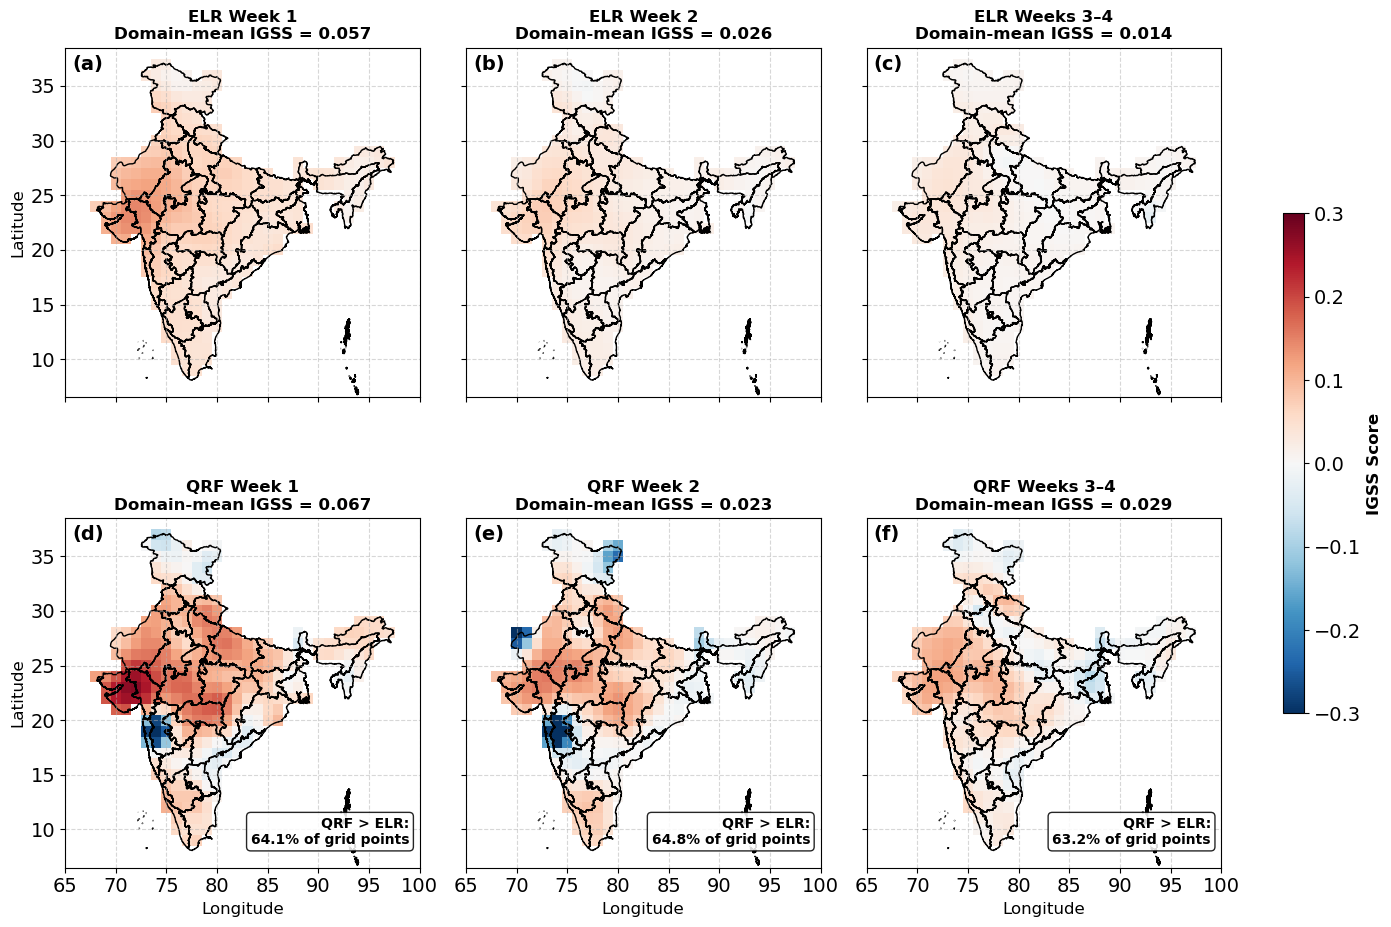

In [13]:
import matplotlib.pyplot as plt
import xarray as xr
import numpy as np

# =========================================================
# DEFINE WEEKS AND TITLES
# =========================================================
weekn = [1, 2, 34]
titles = ['Week 1', 'Week 2', 'Weeks 3–4']

title_fontsize = 12
label_fontsize = 12
tick_fontsize = 14
colorbar_fontsize = 12

# =========================================================
# CREATE FIGURE
# =========================================================
fig, axes = plt.subplots(
    nrows=2,
    ncols=3,
    figsize=(14, 10),
    sharex=True,
    sharey=True
)

plt.subplots_adjust(
    wspace=0.05,
    hspace=0.20
)

# =========================================================
# COLOR SETTINGS
# =========================================================
igss_cmap = 'RdBu_r'
igss_vmin = -0.3
igss_vmax = 0.3

# Store results
domain_igss_results = {}

# =========================================================
# LOOP THROUGH FORECAST LEAD TIMES
# =========================================================
for i, (week, title) in enumerate(zip(weekn, titles)):

    # -----------------------------------------------------
    # Load ELR probabilities
    # -----------------------------------------------------
    elr_probs = xr.open_dataset(
        f'/Users/bohar/Documents/abstract_papers/QRF/'
        f'monsoon_data/ELR_output/'
        f'ELR_test_prob_Week{week}_2022_2024.nc'
    )['prcp']

    # -----------------------------------------------------
    # Load QRF probabilities
    # -----------------------------------------------------
    qrf_prob = np.load(
        f'/Users/bohar/Documents/abstract_papers/QRF/'
        f'monsoon_data/QRF_output/'
        f'week_{week}_tuned_terciles_2022_2024.npy'
    )

    # -----------------------------------------------------
    # Load observed categories
    # -----------------------------------------------------
    classes = xr.open_dataset(
        f'/Users/bohar/Documents/abstract_papers/QRF/'
        f'monsoon_data/ELR_output/'
        f'ELR_test_category_Week{week}_2022_2024.nc'
    )['prcp']

    # -----------------------------------------------------
    # Coordinates
    # -----------------------------------------------------
    Y = elr_probs.coords["Y"]
    X = elr_probs.coords["X"]
    T = elr_probs.coords["T"]

    # -----------------------------------------------------
    # Reformat QRF probabilities
    # -----------------------------------------------------
    qrf_prob_rotated = np.transpose(
        qrf_prob,
        axes=(2, 3, 0, 1)
    )

    qrf_probs = xr.DataArray(
        qrf_prob_rotated,
        dims=elr_probs.dims,
        coords=elr_probs.coords,
        name="qrf_probs"
    )

    # =====================================================
    # COMPUTE IGSS
    # =====================================================
    igss_elr = compute_igss_grid(
        elr_probs,
        classes,
        epsilon=1e-6
    )

    igss_qrf = compute_igss_grid(
        qrf_probs,
        classes,
        epsilon=1e-6
    )

    # =====================================================
    # DOMAIN-MEAN IGSS
    # =====================================================
    # Use UNSMOOTHED fields
    # =====================================================
    domain_mean_igss_elr = igss_elr.mean(
        skipna=True
    ).item()

    domain_mean_igss_qrf = igss_qrf.mean(
        skipna=True
    ).item()

    domain_mean_igss_diff = (
        domain_mean_igss_qrf
        - domain_mean_igss_elr
    )

    # =====================================================
    # PERCENTAGE OF GRID POINTS WHERE QRF > ELR
    # =====================================================
    # Only compare grid points for which BOTH methods
    # have valid IGSS values.
    # =====================================================
    elr_values = igss_elr.values
    qrf_values = igss_qrf.values

    valid_mask = (
        np.isfinite(elr_values)
        & np.isfinite(qrf_values)
    )

    total_valid_points = np.sum(valid_mask)

    qrf_better_points = np.sum(
        (qrf_values > elr_values)
        & valid_mask
    )

    elr_better_points = np.sum(
        (elr_values > qrf_values)
        & valid_mask
    )

    equal_points = np.sum(
        np.isclose(
            qrf_values,
            elr_values,
            atol=1e-12
        )
        & valid_mask
    )

    percent_qrf_better = (
        100.0 * qrf_better_points / total_valid_points
        if total_valid_points > 0 else np.nan
    )

    percent_elr_better = (
        100.0 * elr_better_points / total_valid_points
        if total_valid_points > 0 else np.nan
    )

    # -----------------------------------------------------
    # Store results
    # -----------------------------------------------------
    domain_igss_results[week] = {
        "ELR_mean": domain_mean_igss_elr,
        "QRF_mean": domain_mean_igss_qrf,
        "QRF_minus_ELR": domain_mean_igss_diff,
        "QRF_better_percent": percent_qrf_better,
        "ELR_better_percent": percent_elr_better,
        "valid_grid_points": total_valid_points
    }

    # =====================================================
    # PRINT RESULTS
    # =====================================================
    print("\n--------------------------------------")
    print(title)
    print("--------------------------------------")

    print(
        f"ELR domain-mean IGSS = "
        f"{domain_mean_igss_elr:.4f}"
    )

    print(
        f"QRF domain-mean IGSS = "
        f"{domain_mean_igss_qrf:.4f}"
    )

    print(
        f"QRF - ELR difference = "
        f"{domain_mean_igss_diff:+.4f}"
    )

    print(
        f"QRF IGSS > ELR IGSS at "
        f"{percent_qrf_better:.1f}% of grid points"
    )

    print(
        f"ELR IGSS > QRF IGSS at "
        f"{percent_elr_better:.1f}% of grid points"
    )

    print(
        f"Valid grid points = "
        f"{total_valid_points}"
    )

    # =====================================================
    # SMOOTH FIELDS FOR PLOTTING ONLY
    # =====================================================
    smelr_igss = smooth_xarray_with_nan(
        igss_elr,
        sigma=1
    )

    smqrf_igss = smooth_xarray_with_nan(
        igss_qrf,
        sigma=1
    )

    # =====================================================
    # TOP ROW: ELR
    # =====================================================
    ax_elr = axes[0, i]

    im_elr = smelr_igss.plot(
        ax=ax_elr,
        cmap=igss_cmap,
        vmin=igss_vmin,
        vmax=igss_vmax,
        add_colorbar=False
    )

    gdf_st.plot(
        ax=ax_elr,
        color="none",
        edgecolor="black",
        linewidth=1
    )

    ax_elr.set_title(
        f'ELR {title}\n'
        f'Domain-mean IGSS = {domain_mean_igss_elr:.3f}',
        fontsize=title_fontsize,
        weight='bold'
    )

    # =====================================================
    # BOTTOM ROW: QRF
    # =====================================================
    ax_qrf = axes[1, i]

    im_qrf = smqrf_igss.plot(
        ax=ax_qrf,
        cmap=igss_cmap,
        vmin=igss_vmin,
        vmax=igss_vmax,
        add_colorbar=False
    )

    gdf_st.plot(
        ax=ax_qrf,
        color="none",
        edgecolor="black",
        linewidth=1
    )

    ax_qrf.set_title(
        f'QRF {title}\n'
        f'Domain-mean IGSS = {domain_mean_igss_qrf:.3f}',
        fontsize=title_fontsize,
        weight='bold'
    )

    # =====================================================
    # ADD QRF > ELR GRID-PERCENTAGE IN WHITE SPACE
    # =====================================================
    # Lower-right part of QRF panel is mostly ocean/white.
    # bbox ensures text remains readable.
    # =====================================================
    ax_qrf.text(
        0.97,
        0.06,
        f'QRF > ELR:\n{percent_qrf_better:.1f}% of grid points',
        transform=ax_qrf.transAxes,
        fontsize=10,
        fontweight='bold',
        ha='right',
        va='bottom',
        bbox=dict(
            facecolor='white',
            edgecolor='black',
            alpha=0.85,
            boxstyle='round,pad=0.3'
        )
    )


# =========================================================
# PANEL LABELS, TICKS AND GRID
# =========================================================
panel_number = 0

for ax in axes.flatten():

    ax.tick_params(
        axis='both',
        labelsize=tick_fontsize
    )

    ax.grid(
        True,
        linestyle="--",
        alpha=0.5
    )

    ax.text(
        0.02,
        0.98,
        f"({chr(97 + panel_number)})",
        transform=ax.transAxes,
        fontsize=14,
        weight='bold',
        va='top',
        ha='left',
        color='black'
    )

    panel_number += 1


# =========================================================
# AXIS LABELS
# =========================================================
for row in range(2):

    for col in range(3):

        # Latitude only on left column
        if col == 0:

            axes[row, col].set_ylabel(
                "Latitude",
                fontsize=label_fontsize
            )

        else:

            axes[row, col].set_ylabel("")

        # Longitude only on bottom row
        if row == 1:

            axes[row, col].set_xlabel(
                "Longitude",
                fontsize=label_fontsize
            )

        else:

            axes[row, col].set_xlabel("")


# =========================================================
# LONGITUDE TICKS
# =========================================================
min_longitude = X.min().item()
max_longitude = X.max().item()

longitude_ticks = np.arange(
    np.floor(min_longitude / 5) * 5,
    np.ceil(max_longitude / 5) * 5 + 1,
    5
)

for ax in axes[1, :]:

    ax.set_xticks(
        longitude_ticks
    )


# =========================================================
# SHARED COLORBAR
# =========================================================
cbar_ax = fig.add_axes(
    [0.92, 0.25, 0.015, 0.5]
)

cbar = fig.colorbar(
    im_qrf,
    cax=cbar_ax
)

cbar.set_label(
    "IGSS Score",
    fontsize=colorbar_fontsize,
    fontweight='bold'
)

cbar.ax.tick_params(
    labelsize=tick_fontsize
)


# =========================================================
# LAYOUT
# =========================================================
plt.tight_layout(
    rect=[0, 0, 0.90, 1]
)


# =========================================================
# SAVE FIGURE
# =========================================================
plt.savefig(
    "/Users/bohar/Documents/abstract_papers/QRF/"
    "figures/IGSS_plot_nov26.pdf",
    format="pdf",
    dpi=300,
    bbox_inches="tight"
)

plt.show()